# Part 2: Check the estimates

Replay `traces/azure_conversation.csv` in Vidur (vLLM, one simulated A100-80GB), compare it with your Part 1 predictions, then look at what Part 1 could not see: the time between output tokens. Run from the repo root:

```bash
QPS=5.53 bash scripts/run_default.sh traces/azure_conversation.csv
```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path.cwd()
if not (ROOT / "traces").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from analysis.replay import load_run
from analysis.workload import kv_in_use, load_trace, predict_queue_wait

WAIT_TARGET_S = 2.0    # P99 wait under 2 s (Part 1)
TBT_TARGET_S = 0.100   # P99 time between tokens under 100 ms
BIN_S = 30.0

trace = load_trace(ROOT / "traces" / "azure_conversation.csv")
predicted_wait = predict_queue_wait(trace)
predicted_kv = kv_in_use(trace, predicted_wait, BIN_S)

RUN = ROOT / "simulator_output" / "2026-10-24_18-24-51-182557"   # your vLLM run
run = load_run(RUN, trace)
req, kv = run["requests"], run["kv"]

## Predicted vs measured

                                 predicted         Vidur
P99 wait (s)                          72.1         128.8
longest stretch above 2 s      1192-2272 s   1340-2491 s
requests waiting over 2 s              36%           41%
peak KV cache (GiB)                   26.7          23.8


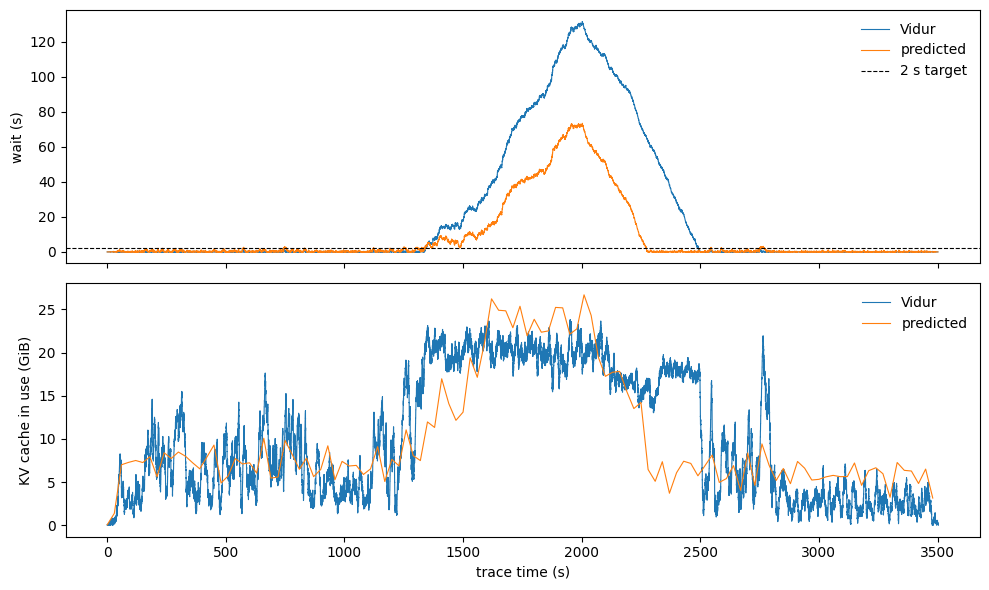

In [2]:
t = req.arrived_at.to_numpy()

def longest_late_stretch(wait, merge_gap_s=60.0):
    """Longest time range where requests wait over the target (gaps under a minute merged)."""
    late = t[wait > WAIT_TARGET_S]
    if len(late) == 0:
        return "never"
    breaks = np.flatnonzero(np.diff(late) > merge_gap_s)
    starts, ends = np.r_[late[0], late[breaks + 1]], np.r_[late[breaks], late[-1]]
    i = np.argmax(ends - starts)
    return f"{starts[i]:.0f}-{ends[i]:.0f} s"

print(f"{'':28s}{'predicted':>14s}{'Vidur':>14s}")
print(f"{'P99 wait (s)':28s}{np.quantile(predicted_wait, .99):14.1f}{req.wait.quantile(.99):14.1f}")
print(f"{'longest stretch above 2 s':28s}{longest_late_stretch(predicted_wait):>14s}{longest_late_stretch(req.wait.to_numpy()):>14s}")
print(f"{'requests waiting over 2 s':28s}{np.mean(predicted_wait > WAIT_TARGET_S):14.0%}{np.mean(req.wait > WAIT_TARGET_S):14.0%}")
print(f"{'peak KV cache (GiB)':28s}{predicted_kv.kv_gib.max():14.1f}{kv.kv_gib.max():14.1f}")

fig, (ax0, ax1) = plt.subplots(2, 1, figsize=(10, 6), sharex=True)
ax0.plot(t, req.wait, label="Vidur", linewidth=0.8)
ax0.plot(t, predicted_wait, label="predicted", linewidth=0.8)
ax0.axhline(WAIT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="2 s target")
ax0.set_ylabel("wait (s)")
ax0.legend(frameon=False)
ax1.plot(kv.time, kv.kv_gib, label="Vidur", linewidth=0.8)
ax1.plot(predicted_kv.bin_start, predicted_kv.kv_gib, label="predicted", linewidth=0.8)
ax1.set_ylabel("KV cache in use (GiB)")
ax1.set_xlabel("trace time (s)")
ax1.legend(frameon=False)
fig.tight_layout()
plt.show()

## Time between tokens

time between tokens: P50 17 ms   P90 131 ms   P99 563 ms   longest 6.6 s


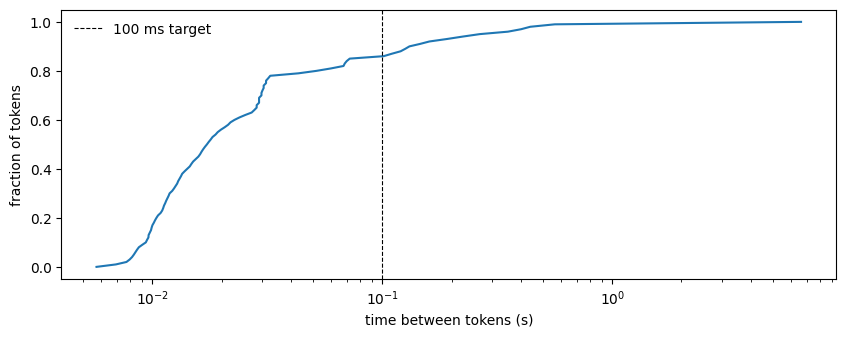

In [3]:
tbt = run["tbt"].set_index("percentile").seconds
print(f"time between tokens: P50 {tbt[50]*1e3:.0f} ms   P90 {tbt[90]*1e3:.0f} ms   P99 {tbt[99]*1e3:.0f} ms   longest {tbt[100]:.1f} s")

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(tbt.to_numpy(), tbt.index / 100)
ax.axvline(TBT_TARGET_S, color="k", linestyle="--", linewidth=0.8, label="100 ms target")
ax.set_xscale("log")
ax.set_xlabel("time between tokens (s)")
ax.set_ylabel("fraction of tokens")
ax.legend(frameon=False)
plt.show()

## Questions

**Q1.** Compare your Part 1 predictions with Vidur: P99 wait, the longest stretch above the 2 s target, and peak KV-cache memory. Which held and which did not? For any that missed, say what the Part 1 model left out.

Prediction 	Value
P99 wait 	72.13 s
Longest stretch above the 2 s target 	1192-2272 s
Peak KV-cache memory (GiB) 	26.7 GiB
Native QPS 	5.53 requests/s

   Vidur
P99 wait (s)                         128.8
longest stretch above 2 s      1340-2491 s
requests waiting over 2 s                41%
peak KV cache (GiB)                       23.8

**Your answer:** P99 wait for Vidur is almost 2x longer than that of the predicted one. Surprisingly, peak KV cache memory for Vidur is 2.9 GiB smaller than the predicted value, and they match well together. The longest stretch above 2s for Vidur is slightly longer on Vidur (71 s longer), but nothing compared to the difference for P99 wait. 
The reason the P99 wait is longer on Vidur is that we assumed that the GPU always runs at the fastest speed, and processes each request sequentially in FCFS order, as we had 12000 tok/s for prefill and 4267 tok/s for decode. However, Vidur's vLLM uses an iteration for the prompt of a request that is waiting to be processed, and the requests that are already being generated do not get the next token in that iteration, delaying the requests still waiting to start.

**Q2.** The target for time between tokens is **P99 under 100 ms**. Does vLLM meet it? Report the P50, P99, and longest time between tokens. What does the longest one mean for a user reading the answer?

**Your answer:** No.　The P50 time between tokens is 17 ms, the P99 is 563 ms, and the longest is 6.6 s. The P99 is well above the 100 ms target. The longest gap means a user reading the answer sees it freeze mid-response for 6.6 s before the next one appears.

**Q3.** What causes the longest gaps between tokens you found in Q2? Read `_get_next_batch` in `vidur/scheduler/replica_scheduler/vllm_replica_scheduler.py`: when new requests are waiting, what goes into the next iteration, and what has to wait?

**Your answer:** When new requests are waiting and one can be admitted, the next iteration is used for those waiting requests' whole prompts, not the ones that have already finished the prefill process. The _get_next_batch function returns as soon as it has added any of them, so the requests that are already being generated do not get the next token in that iteration and have to wait. A long prompt can take the whole iteration, and the running request waits until it finishes. That wait is the 6.6 s gap in Q2.



**Q4.** Part 3 fixes this by capping each iteration at a token budget C: every running request gets its one token, and waiting prompts fill the rest of the budget in chunks. One pass with C tokens (decode and prompt tokens together) takes about **6 ms + C × 78 µs** (Vidur's measured prefill time). Predict the P99 time between tokens for C = 256, 512, and 2048. Which meet the 100 ms target? What happens to the fixed 6 ms per pass, and so to throughput and the queue, when the same prompts take more passes?

| C | Predicted P99 time between tokens |
|---|---|
| 256 |26.0 ms|
| 512 |45.9 ms|
| 2048 |165.7 ms|

**Your answer:**
C=256 and C=512 meet the 100 ms target, C=2048 does not. The 6 ms is paid on every pass, so the same prompts pay it once per pass. Throughput, which is C/(6 ms + C x 78 µs), falls as C gets smaller, and the queue grows.